Hospital composite score (and ZIP-level score)

A **weighted sum of five interpretable subscores**, each on a 0-100 scale. A hospital's composite answers *"how good is this hospital overall"*; the subscores answer *"what is it good for"*.

## How the score is built
1. **Measure score (0-100):** every measure becomes a percentile among hospitals, flipped so **higher is always better** (e.g. a 90 on mortality means a lower death rate than 90% of hospitals). ED-time measures are ranked only against hospitals of the same ED volume tier, so busy and quiet EDs aren't compared directly.
2. **Subscore (0-100):** weighted average of the available measure scores in a category (weights in `scoring_config`).
3. **Composite (0-100):** weighted sum of subscores. If a category is missing, the remaining weights are rescaled; at least 3 of 5 categories are required. Each category's contribution in points is saved (`pts_*`), so the composite can be taken apart.

| Subscore | Default weight | Built from |
|---|---|---|
| Patient safety | 25% | PSI 90 composite, deaths after serious surgical complications, hip/knee complications |
| Survival (mortality) | 25% | hospital-wide and condition-specific 30-day death rates |
| Emergency care | 15% | ED time, left-before-seen, head CT timeliness |
| Effective care | 15% | sepsis bundle, VTE prevention, staff flu vaccination, opioid safety, colonoscopy follow-up, stroke antithrombotic |
| Patient experience | 20% | HCAHPS "top-box" percentages (nurse/doctor communication, medicines, discharge, cleanliness, quiet, overall rating, recommend) |

## What "CMS star rating" means here
The only star ratings in your data are the **HCAHPS Summary Star Rating** (patient experience only, 3,183 hospitals), *not* CMS's Overall Hospital Quality Star Rating. Validation therefore has three parts: **(a)** the full composite vs stars, **(b)** a **clinical-only composite** (no HCAHPS inputs) vs stars, which is the fair test because stars are built from the same survey, and **(c)** the experience subscore vs stars as a construction check (expected to be very high). Weights are **not tuned to the stars**; a sensitivity analysis shows how much the result depends on the weights.

## 0. Setup and configuration

In [3]:
import os, re, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

# ---------- locate the project (works whether the notebook is run from Scoring_system/ or the project root) ----------
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if any((p / d).is_dir() for d in ("Data_standard", "Data_clean", "Data")):
            return p
    return start
ROOT = find_root()                                         # e.g. .../csds_capstone
SEARCH_ORDER = ["Data_clean", "Data_standard", "Data", "database", "data_cleaning"]   # looked in first, in this order
OUT_DIR = ROOT / "Scoring_system" / "outputs"              # everything this notebook writes
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

def find(name, required=True):
    """Find a file by name: known folders first, then anywhere under the project root."""
    for d in SEARCH_ORDER:
        p = ROOT / d / name
        if p.exists(): return p
    hits = [p for p in ROOT.rglob(name) if not any(part.startswith(".") or part in ("venv", "node_modules", "__pycache__") for part in p.relative_to(ROOT).parts)]
    if hits: return min(hits, key=lambda p: len(p.parts))
    if required: raise FileNotFoundError(f"Could not find {name} under {ROOT}. Looked in {SEARCH_ORDER}, then searched all subfolders.")
    return None

print("project root:", ROOT)
print("outputs go to:", OUT_DIR)

# ---------- category weights (edit these) ----------
CATEGORY_WEIGHTS = {"safety": 0.25, "survival": 0.25, "emergency": 0.15, "effective": 0.15, "experience": 0.20}
CATEGORY_LABELS  = {"safety": "Patient safety", "survival": "Survival (mortality)", "emergency": "Emergency care",
                    "effective": "Effective care", "experience": "Patient experience"}
CLINICAL = ["safety", "survival", "emergency", "effective"]          # categories with no HCAHPS input
MIN_MEASURES = {"safety": 1, "survival": 1, "emergency": 1, "effective": 2, "experience": 4}   # measures needed to score a category
MIN_CATEGORIES = 3                 # categories needed to give a composite
MIN_PEER_GROUP = 30                # smallest peer group used for ED-time ranking

# ---------- measure config: (measure_id, category, weight within category, better direction, peer group, source) ----------
CFG = pd.DataFrame([
 ("PSI_90","safety",2,"lower","","cms"),("PSI_04","safety",1,"lower","","cms"),("COMP_HIP_KNEE","safety",1,"lower","","cms"),
 ("Hybrid_HWM","survival",3,"lower","","cms"),("MORT_30_AMI","survival",1,"lower","","cms"),("MORT_30_HF","survival",1,"lower","","cms"),
 ("MORT_30_PN","survival",1,"lower","","cms"),("MORT_30_COPD","survival",1,"lower","","cms"),("MORT_30_STK","survival",1,"lower","","cms"),
 ("MORT_30_CABG","survival",1,"lower","","cms"),
 ("OP_18a","emergency",2,"lower","edv","cms"),("OP_22","emergency",1,"lower","edv","cms"),("OP_23","emergency",1,"higher","","cms"),
 ("SEP_1","effective",1,"higher","","cms"),("VTE_1","effective",1,"higher","","cms"),("IMM_3","effective",1,"higher","","cms"),
 ("SAFE_USE_OF_OPIOIDS","effective",1,"lower","","cms"),("OP_29","effective",1,"higher","","cms"),("STK_02","effective",1,"higher","","cms"),
 ("h_comp_1_a_p","experience",1,"higher","","hcahps"),("h_comp_2_a_p","experience",1,"higher","","hcahps"),("h_comp_5_a_p","experience",1,"higher","","hcahps"),
 ("h_comp_6_y_p","experience",1,"higher","","hcahps"),("h_clean_hsp_a_p","experience",1,"higher","","hcahps"),("h_quiet_hsp_a_p","experience",1,"higher","","hcahps"),
 ("h_hsp_rating_9_10","experience",1,"higher","","hcahps"),("h_recmnd_dy","experience",1,"higher","","hcahps"),
], columns=["measure_id","category","weight","direction","peer","source"])

# "What is it good for": condition-level strengths (percentile of these measures)
SPECIALTIES = {"Heart attack care": ["MORT_30_AMI"], "Heart failure care": ["MORT_30_HF"], "Pneumonia care": ["MORT_30_PN"],
               "COPD care": ["MORT_30_COPD"], "Stroke care": ["MORT_30_STK", "STK_02"], "Heart bypass surgery": ["MORT_30_CABG"],
               "Joint replacement": ["COMP_HIP_KNEE"], "Sepsis care": ["SEP_1"]}
STRONG_CAT, WEAK_CAT, STRONG_SPEC = 75, 25, 80       # thresholds on the 0-100 scale
RNG = np.random.default_rng(42)
assert abs(sum(CATEGORY_WEIGHTS.values()) - 1) < 1e-9

project root: c:\Users\bhoom\Documents\GitHub\CSDS_coursework\CSDS 398\csds_capstone
outputs go to: c:\Users\bhoom\Documents\GitHub\CSDS_coursework\CSDS 398\csds_capstone\Scoring_system\outputs


## 1. Load data
Files are found by name (see `find()` in the setup cell): `Data_clean/` then `Data_standard/` then `Data/` then any other project folder. Hospital list and type come from `cms_hospitals_rows.csv` (or `Hospital_General_Information.csv` if that is missing); measures from the facility files; patient experience from `hcahps_scores_rows.csv`.

In [4]:
HGI_COLS = {"Facility ID": "facility_id", "Facility Name": "facility_name", "Address": "address", "City/Town": "city", "State": "state", "ZIP Code": "zip_code",
            "County/Parish": "county", "Telephone Number": "telephone_number", "Hospital Type": "hospital_type", "Hospital Ownership": "hospital_ownership",
            "Emergency Services": "emergency_services"}
p_hosp = find("cms_hospitals_rows.csv", required=False)
if p_hosp is not None:
    hosp = pd.read_csv(p_hosp, dtype=str)
else:                                                       # same 5,419 hospitals and columns live in Hospital_General_Information.csv
    p_hosp = find("Hospital_General_Information.csv")
    hosp = pd.read_csv(p_hosp, dtype=str, usecols=list(HGI_COLS)).rename(columns=HGI_COLS)
p_hc  = find("hcahps_scores_rows.csv")
hc    = pd.read_csv(p_hc, dtype={"facility_id": str})
p_fac = [find(f"{n}.csv") for n in ["facility_hospital_complications_deaths", "facility_hospital_timely_effective_care"]]
hm = pd.concat([pd.read_csv(p, dtype={"facility_id": str, "zip": str}, low_memory=False) for p in p_fac], ignore_index=True)
if "flag_implausible_value" in hm:                           # from the cleaning notebook: drop impossible values
    hm.loc[hm["flag_implausible_value"].fillna(False).astype(bool), "score"] = np.nan
for label, p in [("hospital list", p_hosp), ("HCAHPS", p_hc), ("complications/deaths", p_fac[0]), ("timely & effective care", p_fac[1])]:
    print(f"{label:24s} <- {p.relative_to(ROOT)}")
edv = (hm[hm.measure_id == "EDV"].set_index("facility_id")["score_text"].str.lower().str.strip()).rename("ed_volume")
W = hm[hm.score.notna()].pivot(index="facility_id", columns="measure_id", values="score")           # hospitals x measures
H = hc.set_index("facility_id")
raw = W.join(H[[c for c in CFG.measure_id if c.startswith("h_")]], how="outer")
hosp = hosp.set_index("facility_id")
print(f"{len(hosp):,} hospitals in master list | {W.shape[0]:,} with CMS measures | {H.shape[0]:,} in HCAHPS | {H.h_star_rating.notna().sum():,} with an HCAHPS star rating")

hospital list            <- Data_standard\cms_hospitals_rows.csv
HCAHPS                   <- Data_standard\hcahps_scores_rows.csv
complications/deaths     <- Data_standard\facility_hospital_complications_deaths.csv
timely & effective care  <- Data_standard\facility_hospital_timely_effective_care.csv
5,419 hospitals in master list | 4,582 with CMS measures | 4,790 in HCAHPS | 3,183 with an HCAHPS star rating


## 2. Measure scores: percentile, higher = better

In [5]:
def pct_score(s, direction, peer=None):
    """Percentile 0-100 among hospitals with a value; higher is always better. Optional peer groups (min size MIN_PEER_GROUP)."""
    s = s.dropna(); asc = (direction == "higher")
    one = lambda x: (x.rank(ascending=asc) - 0.5) / x.count() * 100
    national = one(s)
    if peer is None: return national
    p = peer.reindex(s.index).fillna("unknown")
    within = s.groupby(p).transform(lambda x: one(x) if x.count() >= MIN_PEER_GROUP else np.nan)
    return within.fillna(national)

P = pd.DataFrame(index=raw.index)
for _, r in CFG.iterrows():
    P[r.measure_id] = pct_score(raw[r.measure_id], r.direction, edv if r.peer == "edv" else None)
print("measure scores:", P.shape, "| coverage min/median/max:", P.notna().sum().min(), int(P.notna().sum().median()), P.notna().sum().max())

measure scores: (4790, 27) | coverage min/median/max: 861 3639 4261


## 3. Subscores, composite, contributions, tiers and plain-language summary

In [6]:
def weighted_mean(frame, weights):
    w = pd.Series(weights).reindex(frame.columns)
    num = (frame * w).sum(axis=1, skipna=True)
    den = (frame.notna() * w).sum(axis=1)
    return num / den.replace(0, np.nan)

def category_scores(P):
    S = pd.DataFrame(index=P.index)
    for cat in CATEGORY_WEIGHTS:
        c = CFG[CFG.category == cat]; sub = P[c.measure_id]
        s = weighted_mean(sub, dict(zip(c.measure_id, c.weight)))
        S[cat] = s.where(sub.notna().sum(axis=1) >= MIN_MEASURES[cat])
    return S

def composite(S, weights, cats=None, min_cats=MIN_CATEGORIES):
    cats = cats or list(weights); w = pd.Series({k: weights[k] for k in cats})
    X = S[cats]; ok = X.notna().sum(axis=1) >= min_cats
    return (weighted_mean(X, w)).where(ok)

S = category_scores(P)
S["composite"]          = composite(S, CATEGORY_WEIGHTS)
S["clinical_composite"] = composite(S, CATEGORY_WEIGHTS, CLINICAL, min_cats=2)       # no HCAHPS inputs
S["n_categories"]       = S[list(CATEGORY_WEIGHTS)].notna().sum(axis=1)
# conservative version: a missing category counts as a typical hospital (50), so hospitals with little data can't rank at the extremes on thin evidence
S["composite_conservative"] = (S[list(CATEGORY_WEIGHTS)].fillna(50) * pd.Series(CATEGORY_WEIGHTS)).sum(axis=1).where(S.composite.notna())

# points contributed by each category (they add up to the composite)
w = pd.Series(CATEGORY_WEIGHTS); avail = S[list(w.index)].notna() * w
share = avail.div(avail.sum(axis=1).replace(0, np.nan), axis=0)
for cat in w.index: S[f"pts_{cat}"] = (S[cat] * share[cat]).where(S.composite.notna())

# specialties
SP = pd.DataFrame({k: P[v].mean(axis=1) for k, v in SPECIALTIES.items()})

# percentile of the composite and tier labels
S["composite_percentile"] = S.composite.rank(pct=True) * 100
S["tier"] = pd.cut(S.composite_percentile, [0, 10, 30, 70, 90, 100.01], labels=["Poor (bottom 10%)", "Below average", "Average", "Good", "Excellent (top 10%)"], include_lowest=True)
S["confidence"] = S.n_categories.map({5: "High (5 of 5 categories)", 4: "Medium (4 of 5)", 3: "Lower (3 of 5)"})

def describe(fid):
    r, sp = S.loc[fid], SP.loc[fid]
    good = [CATEGORY_LABELS[c] for c in CATEGORY_WEIGHTS if pd.notna(r[c]) and r[c] >= STRONG_CAT]
    good += [k for k, v in sp.items() if pd.notna(v) and v >= STRONG_SPEC]
    weak = [CATEGORY_LABELS[c] for c in CATEGORY_WEIGHTS if pd.notna(r[c]) and r[c] <= WEAK_CAT]
    return "; ".join(good), "; ".join(weak)
txt = {f: describe(f) for f in S.index[S.composite.notna()]}
S["good_for"]  = pd.Series({f: t[0] for f, t in txt.items()})
S["watch_out"] = pd.Series({f: t[1] for f, t in txt.items()})
print(S[["composite", "clinical_composite"]].describe().round(1).T)
print(S.n_categories.value_counts().sort_index().to_dict(), "| scored hospitals:", S.composite.notna().sum())
top100 = S.composite.nlargest(100).index
print(f"Caution: {(S.loc[top100, 'n_categories'] < 5).sum()} of the 100 highest composites have fewer than 5 categories of data; use composite_conservative / confidence when ranking.")

                     count  mean   std   min   25%   50%   75%   max
composite           4144.0  49.5  11.6  14.3  41.3  49.5  57.6  92.3
clinical_composite  4332.0  48.7  13.1   5.8  39.7  48.5  57.8  91.8
{0: 243, 1: 177, 2: 226, 3: 477, 4: 971, 5: 2696} | scored hospitals: 4144
Caution: 75 of the 100 highest composites have fewer than 5 categories of data; use composite_conservative / confidence when ranking.


## 4. Hospital score table

In [7]:
star = H.h_star_rating.rename("hcahps_star")
T = (hosp[["facility_name", "city", "state", "zip_code", "county", "hospital_type", "hospital_ownership", "emergency_services"]]
     .rename(columns={"zip_code": "zip"}).join(edv).join(star).join(H.number_of_completed_surveys.rename("hcahps_surveys"))
     .join(S).join(SP.add_prefix("spec_")))
T["rank_national"] = T.composite.rank(ascending=False, method="min")
T["rank_national_conservative"] = T.composite_conservative.rank(ascending=False, method="min")
T["rank_in_state"] = T.groupby("state").composite.rank(ascending=False, method="min")
T["n_scored_in_state"] = T.groupby("state").composite.transform("count")
T["star_as_0_100"] = (T.hcahps_star - 0.5) / 5 * 100          # star put on a 0-100 scale (1 star = 10, 5 stars = 90)
T["gap_vs_star"] = T.composite_percentile - T.star_as_0_100   # positive = composite more favorable than the star
T["status"] = np.select([T.composite.notna(), T.hospital_type.isin(["Psychiatric", "Long-term"]), T.n_categories.fillna(0) == 0],
                        ["scored", "not scored: psychiatric/long-term hospital (no quality data)", "not scored: no usable measures"],
                        "not scored: fewer than 3 categories with data")
T = T.reset_index().rename(columns={"index": "facility_id"})
T.to_csv(OUT_DIR / "hospital_scores.csv", index=False)
print(T.status.value_counts().to_dict())
T[T.composite.notna()].sort_values("composite", ascending=False)[["facility_name", "state", "composite", "tier", "hcahps_star", "good_for", "watch_out"]].head(8)

{'scored': 4144, 'not scored: psychiatric/long-term hospital (no quality data)': 629, 'not scored: fewer than 3 categories with data': 403, 'not scored: no usable measures': 243}


,facility_name,state,composite,tier,hcahps_star,good_for,watch_out
3516,FARGO VA MEDICAL CENTER,ND,92.334281,Excellent (top 10%),5.0,Patient safety; Survival (mortality); Patient ...,
3864,CREEK NATION COMMUNITY HOSPITAL,OK,86.378390,Excellent (top 10%),NaN,Survival (mortality); Emergency care; Effectiv...,
3315,HOSPITAL FOR SPECIAL SURGERY,NY,85.463895,Excellent (top 10%),4.0,Patient safety; Survival (mortality); Joint re...,
4287,BLACK HILLS SURGICAL HOSPITAL LLC,SD,85.258674,Excellent (top 10%),5.0,Patient safety; Survival (mortality); Patient ...,
5177,MADISON VA MEDICAL CENTER,WI,85.081832,Excellent (top 10%),5.0,Patient safety; Survival (mortality); Patient ...,
2079,SOUTHEAST LOUISIANA VETERANS HEALTH CARE SYSTEM,LA,83.911131,Excellent (top 10%),4.0,Patient safety; Survival (mortality); Patient ...,
1789,KANSAS CITY ORTHOPAEDIC INSTITUTE,KS,83.405135,Excellent (top 10%),5.0,Patient safety; Survival (mortality); Patient ...,
4259,COLUMBIA SC VA MEDICAL CENTER,SC,83.220291,Excellent (top 10%),5.0,Patient safety; Survival (mortality); Patient ...,


## 5. Validation against CMS (HCAHPS) star ratings: Spearman's rho
Bootstrapped 95% confidence intervals (1,000 resamples).

In [8]:
def rho_ci(x, y, n_boot=1000):
    d = pd.concat([x, y], axis=1).dropna(); a, b = d.iloc[:, 0].values, d.iloc[:, 1].values
    if len(d) < 30: return dict(n=len(d), rho=np.nan, p=np.nan, ci_low=np.nan, ci_high=np.nan)
    rho, p = spearmanr(a, b)
    boots = [spearmanr(a[i], b[i])[0] for i in (RNG.integers(0, len(d), len(d)) for _ in range(n_boot))]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return dict(n=len(d), rho=rho, p=p, ci_low=lo, ci_high=hi)

rows = []
def add(test, kind, x, y): rows.append(dict(test=test, kind=kind, **rho_ci(x, y)))
st = T.set_index("facility_id").hcahps_star; Ti = T.set_index("facility_id")
add("Composite (all 5 categories) vs HCAHPS star", "main result", Ti.composite, st)
add("Clinical-only composite (no HCAHPS inputs) vs HCAHPS star", "independent test", Ti.clinical_composite, st)
add("Conservative composite (missing = 50) vs HCAHPS star", "variant", Ti.composite_conservative, st)
for cat in CATEGORY_WEIGHTS:
    add(f"{CATEGORY_LABELS[cat]} subscore vs HCAHPS star", "construction check" if cat == "experience" else "subscore", Ti[cat], st)
# experience measures vs their own topic star
topic = {"h_comp_1_a_p": "h_comp_1_star_rating", "h_comp_2_a_p": "h_comp_2_star_rating", "h_comp_5_a_p": "h_comp_5_star_rating", "h_comp_6_y_p": "h_comp_6_star_rating",
         "h_clean_hsp_a_p": "h_clean_star_rating", "h_quiet_hsp_a_p": "h_quiet_star_rating", "h_hsp_rating_9_10": "h_hsp_rating_star_rating", "h_recmnd_dy": "h_recmnd_star_rating"}
for m, s_ in topic.items(): add(f"{m} vs {s_}", "topic check", raw[m], H[s_])
val = pd.DataFrame(rows); val.round(4).to_csv(OUT_DIR / "validation_results.csv", index=False)
val.round(3)

,test,kind,n,rho,p,ci_low,ci_high
0,Composite (all 5 categories) vs HCAHPS star,main result,3170,0.435,0.000,0.407,0.463
1,Clinical-only composite (no HCAHPS inputs) vs ...,independent test,3170,0.060,0.001,0.022,0.093
2,Conservative composite (missing = 50) vs HCAHP...,variant,3170,0.432,0.000,0.403,0.459
3,Patient safety subscore vs HCAHPS star,subscore,2820,0.053,0.005,0.017,0.092
4,Survival (mortality) subscore vs HCAHPS star,subscore,3150,-0.002,0.895,-0.038,0.032
5,Emergency care subscore vs HCAHPS star,subscore,2948,0.036,0.050,-0.000,0.074
6,Effective care subscore vs HCAHPS star,subscore,3050,0.172,0.000,0.134,0.208
7,Patient experience subscore vs HCAHPS star,construction check,3183,0.918,0.000,0.912,0.922
8,h_comp_1_a_p vs h_comp_1_star_rating,topic check,3183,0.940,0.000,0.936,0.944
9,h_comp_2_a_p vs h_comp_2_star_rating,topic check,3183,0.929,0.000,0.924,0.933


### Optional: validate against the CMS *Overall* Hospital Quality Star Rating
The HCAHPS star measures only patient experience, so it cannot validate the clinical subscores. CMS's **Overall Hospital Quality Star Rating** (1-5, built from safety, mortality, readmission and timely-care measures) can. It is in CMS's *Hospital General Information* file (column `Hospital overall rating`). This cell finds `Hospital_General_Information.csv` anywhere in the project (for example `Data_standard/`) and adds the comparison automatically.

In [9]:
ov_path = find("Hospital_General_Information.csv", required=False)
if ov_path is None:
    print("Hospital_General_Information.csv not found anywhere under the project: skipping the Overall Star validation.")
else:
    ov = pd.read_csv(ov_path, dtype=str); ov.columns = [c.strip().lower().replace(" ", "_") for c in ov.columns]
    id_col  = next(c for c in ov.columns if c in ("facility_id", "provider_id", "cms_certification_number"))
    rat_col = next(c for c in ov.columns if "overall" in c and "rating" in c and "footnote" not in c)
    ov_star = pd.to_numeric(ov.set_index(id_col)[rat_col], errors="coerce").rename("cms_overall_star"); ov_star = ov_star[~ov_star.index.duplicated()]
    T = T.merge(ov_star, left_on="facility_id", right_index=True, how="left"); Ti = T.set_index("facility_id")
    new = []
    for name, x in [("Composite (all 5 categories)", Ti.composite), ("Clinical-only composite", Ti.clinical_composite)] + [(CATEGORY_LABELS[c] + " subscore", Ti[c]) for c in CLINICAL]:
        new.append(dict(test=f"{name} vs CMS Overall Star", kind="CMS overall star (external)", **rho_ci(x, Ti.cms_overall_star)))
    val = pd.concat([val, pd.DataFrame(new)], ignore_index=True); val.round(4).to_csv(OUT_DIR / "validation_results.csv", index=False)
    T.to_csv(OUT_DIR / "hospital_scores.csv", index=False)
    print(val[val.kind == "CMS overall star (external)"][["test", "n", "rho", "ci_low", "ci_high"]].round(3).to_string(index=False))

                                             test    n   rho  ci_low  ci_high
 Composite (all 5 categories) vs CMS Overall Star 3153 0.635   0.613    0.657
      Clinical-only composite vs CMS Overall Star 3166 0.519   0.494    0.545
      Patient safety subscore vs CMS Overall Star 2748 0.307   0.275    0.340
Survival (mortality) subscore vs CMS Overall Star 3172 0.455   0.425    0.483
      Emergency care subscore vs CMS Overall Star 2979 0.101   0.065    0.138
      Effective care subscore vs CMS Overall Star 3040 0.297   0.263    0.329


## 6. Sensitivity: how much do the weights matter?
1,000 random weight sets (all five categories, uniformly random on the simplex). Reports (a) rho of each version vs the stars, and (b) rho between each version's ranking and the default ranking.

In [10]:
cats = list(CATEGORY_WEIGHTS); X = S[cats]; M = X.notna().values.astype(float); X0 = X.fillna(0).values
Wr = RNG.dirichlet(np.ones(len(cats)), size=1000).T                       # 5 x 1000
den = M @ Wr; comp_r = pd.DataFrame(np.where((M.sum(axis=1) >= MIN_CATEGORIES)[:, None] & (den > 0), (X0 @ Wr) / np.where(den == 0, np.nan, den), np.nan), index=X.index)
both = comp_r.index.intersection(st.dropna().index).intersection(S.composite.dropna().index)
rho_star = comp_r.loc[both].rank().corrwith(st.loc[both].rank())
rho_def  = comp_r.loc[both].rank().corrwith(S.composite.loc[both].rank())
sens = pd.DataFrame({"rho_vs_star": rho_star, "rho_vs_default_ranking": rho_def})
print(sens.describe().loc[["mean", "min", "25%", "50%", "75%", "max"]].round(3))

      rho_vs_star  rho_vs_default_ranking
mean        0.386                   0.810
min         0.021                   0.500
25%         0.183                   0.751
50%         0.347                   0.820
75%         0.550                   0.883
max         0.909                   0.994


## 7. What the composite adds beyond the star rating

In [11]:
Ti["clin_q"] = pd.qcut(Ti.clinical_composite, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
cross = pd.crosstab(Ti.hcahps_star, Ti.clin_q)
has_comp, has_star = Ti.composite.notna(), Ti.hcahps_star.notna()
added = {
 "hospitals with a composite score": int(has_comp.sum()),
 "of those, with NO HCAHPS star rating": int((has_comp & ~has_star).sum()),
 "hospitals with a star but no composite": int((has_star & ~has_comp).sum()),
 "4-5 star hospitals in the bottom quartile on clinical composite": int(((Ti.hcahps_star >= 4) & (Ti.clin_q == "Q1 (lowest)")).sum()),
 "1-2 star hospitals in the top quartile on clinical composite": int(((Ti.hcahps_star <= 2) & (Ti.clin_q == "Q4 (highest)")).sum()),
 "distinct composite values (scale resolution) vs 5 star levels": int(Ti.composite.round(1).nunique()),
}
for k, v in added.items(): print(f"{v:>7,}  {k}")
spread = Ti.groupby("hcahps_star").composite.describe()[["count", "25%", "50%", "75%"]].round(1)
print("\nComposite within each star level:"); print(spread)
# the composite explains this much of the rank variation in stars
r_main = val.loc[0, "rho"]; print(f"\nSpearman rho^2 = {r_main**2:.2f}: stars account for about {r_main**2:.0%} of the rank variation in the composite")

  4,144  hospitals with a composite score
    974  of those, with NO HCAHPS star rating
     13  hospitals with a star but no composite
    248  4-5 star hospitals in the bottom quartile on clinical composite
    146  1-2 star hospitals in the top quartile on clinical composite
    574  distinct composite values (scale resolution) vs 5 star levels

Composite within each star level:
              count   25%   50%   75%
hcahps_star                          
1.0            59.0  33.8  39.5  46.9
2.0           541.0  35.6  42.3  49.2
3.0          1294.0  40.6  47.6  54.5
4.0          1056.0  46.7  54.3  61.4
5.0           220.0  52.7  58.5  66.4

Spearman rho^2 = 0.19: stars account for about 19% of the rank variation in the composite


## 8. ZIP-code scores
A ZIP's score is the average composite of the scored hospitals in it (all five subscores averaged the same way). `n_hospitals_scored` shows how much to trust it: most ZIPs have just one hospital.

In [12]:
sc = T[T.composite.notna()].copy()
g = sc.groupby("zip")
Z = pd.DataFrame({"n_hospitals_scored": g.size(), "state": g.state.first(), "city": g.city.first(),
                  "zip_score": g.composite.mean(), "best_hospital_score": g.composite.max(), "worst_hospital_score": g.composite.min(),
                  "hcahps_star_mean": g.hcahps_star.mean()})
for cat in CATEGORY_WEIGHTS: Z[cat] = g[cat].mean()
Z["best_hospital"] = sc.loc[g.composite.idxmax(), ["zip", "facility_name"]].set_index("zip").facility_name
Z["zip_percentile"] = Z.zip_score.rank(pct=True) * 100
Z["zip_tier"] = pd.cut(Z.zip_percentile, [0, 10, 30, 70, 90, 100.01], labels=["Poor (bottom 10%)", "Below average", "Average", "Good", "Excellent (top 10%)"], include_lowest=True)
def zip_good_for(r):
    good = [CATEGORY_LABELS[c] for c in CATEGORY_WEIGHTS if pd.notna(r[c]) and r[c] >= STRONG_CAT]
    weak = [CATEGORY_LABELS[c] for c in CATEGORY_WEIGHTS if pd.notna(r[c]) and r[c] <= WEAK_CAT]
    return pd.Series({"good_for": "; ".join(good), "watch_out": "; ".join(weak)})
Z = Z.join(Z.apply(zip_good_for, axis=1)).reset_index()
Z.to_csv(OUT_DIR / "zip_scores.csv", index=False)
zv = rho_ci(Z.set_index("zip").zip_score, Z.set_index("zip").hcahps_star_mean)
print(f"{len(Z):,} ZIPs scored ({(Z.n_hospitals_scored > 1).sum():,} with 2+ hospitals) | ZIP score vs mean HCAHPS star: rho = {zv['rho']:.2f} (n = {zv['n']:,})")
pd.concat([val, pd.DataFrame([dict(test="ZIP composite vs mean HCAHPS star of ZIP", kind="ZIP level", **zv)])]).round(4).to_csv(OUT_DIR / "validation_results.csv", index=False)

3,859 ZIPs scored (239 with 2+ hospitals) | ZIP score vs mean HCAHPS star: rho = 0.42 (n = 2,919)


## 9. Figures: validation

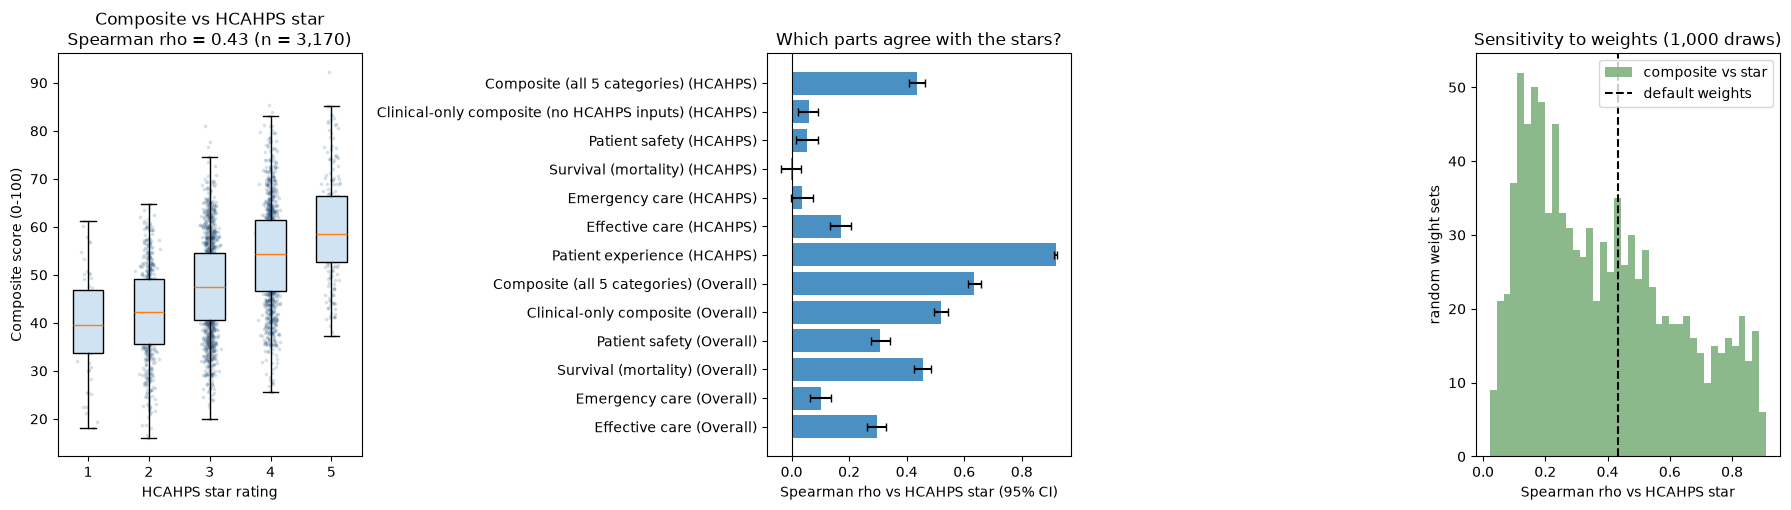

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
# (a) composite by star level
d = Ti.dropna(subset=["composite", "hcahps_star"]); levels = sorted(d.hcahps_star.unique())
ax[0].boxplot([d.loc[d.hcahps_star == l, "composite"] for l in levels], showfliers=False, patch_artist=True, boxprops=dict(facecolor="#cfe3f3"))
ax[0].set_xticks(range(1, len(levels) + 1)); ax[0].set_xticklabels([int(l) for l in levels])
ax[0].scatter(d.hcahps_star + RNG.normal(0, .06, len(d)), d.composite, s=3, alpha=.12, color="#1f4e79")
ax[0].set(xlabel="HCAHPS star rating", ylabel="Composite score (0-100)", title=f"Composite vs HCAHPS star\nSpearman rho = {val.rho[0]:.2f} (n = {int(val.n[0]):,})")
# (b) rho by subscore
b = val[val.kind.isin(["main result", "independent test", "subscore", "construction check", "CMS overall star (external)"])].iloc[::-1]
ax[1].barh(b.test.str.replace(" vs HCAHPS star", " (HCAHPS)").str.replace(" subscore", "").str.replace(" vs CMS Overall Star", " (Overall)"), b.rho, xerr=[b.rho - b.ci_low, b.ci_high - b.rho], color="#4a90c2", capsize=3)
ax[1].axvline(0, color="k", lw=.8); ax[1].set(xlabel="Spearman rho vs HCAHPS star (95% CI)", title="Which parts agree with the stars?")
# (c) weight sensitivity
ax[2].hist(sens.rho_vs_star, bins=40, color="#7fb27f", alpha=.9, label="composite vs star")
ax[2].axvline(val.rho[0], color="k", ls="--", label="default weights")
ax[2].set(xlabel="Spearman rho vs HCAHPS star", ylabel="random weight sets", title="Sensitivity to weights (1,000 draws)"); ax[2].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "validation.png", dpi=150); plt.show()

## 10. Figures: distribution and where stars and composite disagree

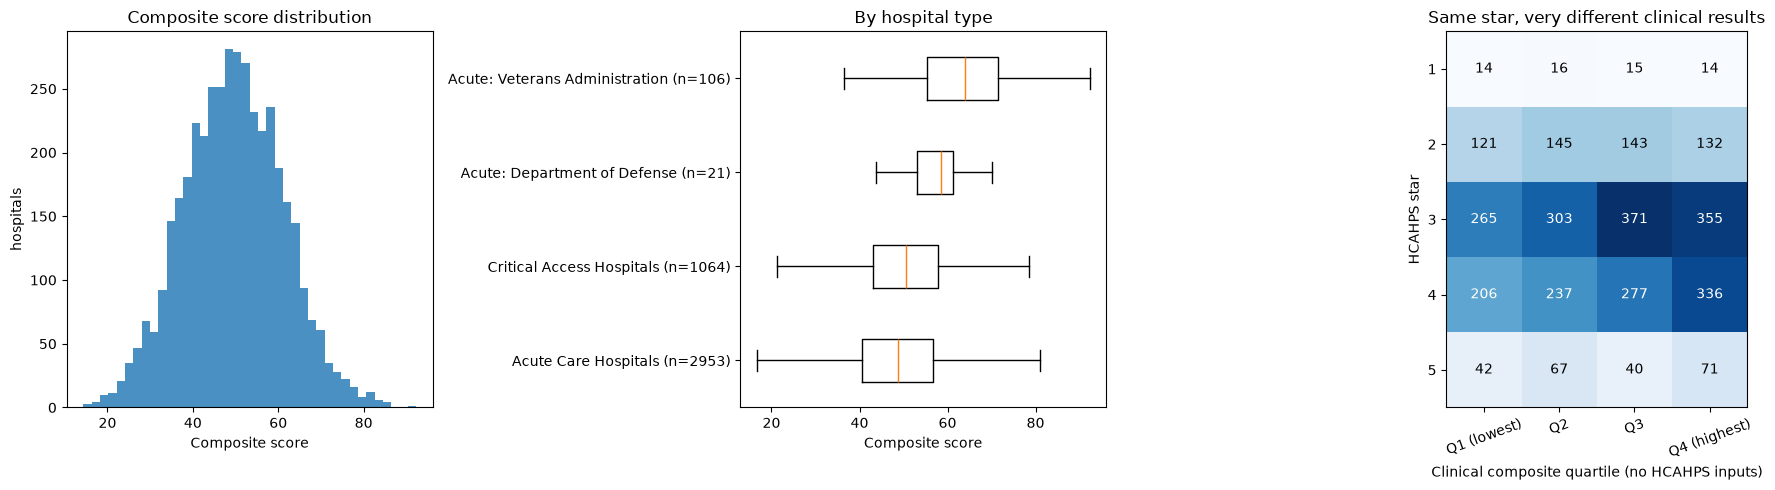

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].hist(T.composite.dropna(), bins=40, color="#4a90c2"); ax[0].set(xlabel="Composite score", ylabel="hospitals", title="Composite score distribution")
tt = T.dropna(subset=["composite"]); order = tt.groupby("hospital_type").composite.median().sort_values().index
ax[1].boxplot([tt.loc[tt.hospital_type == t, "composite"] for t in order], vert=False, showfliers=False)
ax[1].set_yticks(range(1, len(order) + 1)); ax[1].set_yticklabels([f"{t.replace('Acute Care - ', 'Acute: ')} (n={int((tt.hospital_type == t).sum())})" for t in order])
ax[1].set(xlabel="Composite score", title="By hospital type")
im = ax[2].imshow(cross.values, cmap="Blues"); ax[2].set_xticks(range(cross.shape[1])); ax[2].set_xticklabels(cross.columns, rotation=20); ax[2].set_yticks(range(cross.shape[0])); ax[2].set_yticklabels([int(i) for i in cross.index])
for i in range(cross.shape[0]):
    for j in range(cross.shape[1]): ax[2].text(j, i, cross.values[i, j], ha="center", va="center", color="white" if cross.values[i, j] > cross.values.max() / 2 else "black")
ax[2].set(xlabel="Clinical composite quartile (no HCAHPS inputs)", ylabel="HCAHPS star", title="Same star, very different clinical results")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "distribution_and_disagreement.png", dpi=150); plt.show()

## 11. Hospital scorecard: *is it good, and what for?*
`scorecard(facility_id)` draws the subscores against the national median (50), with specialty strengths.


== highest composite


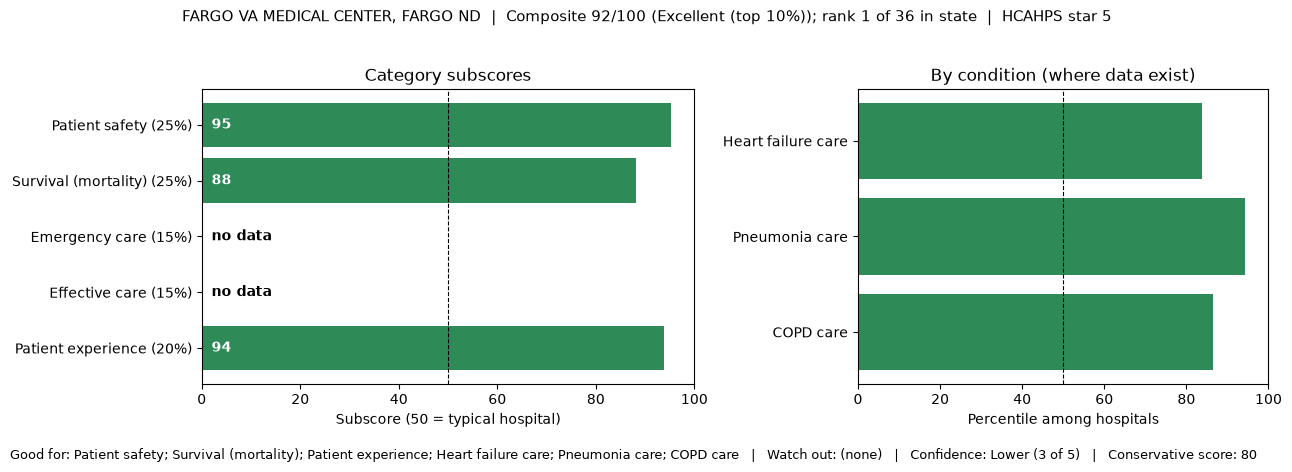


== high star, weak clinical


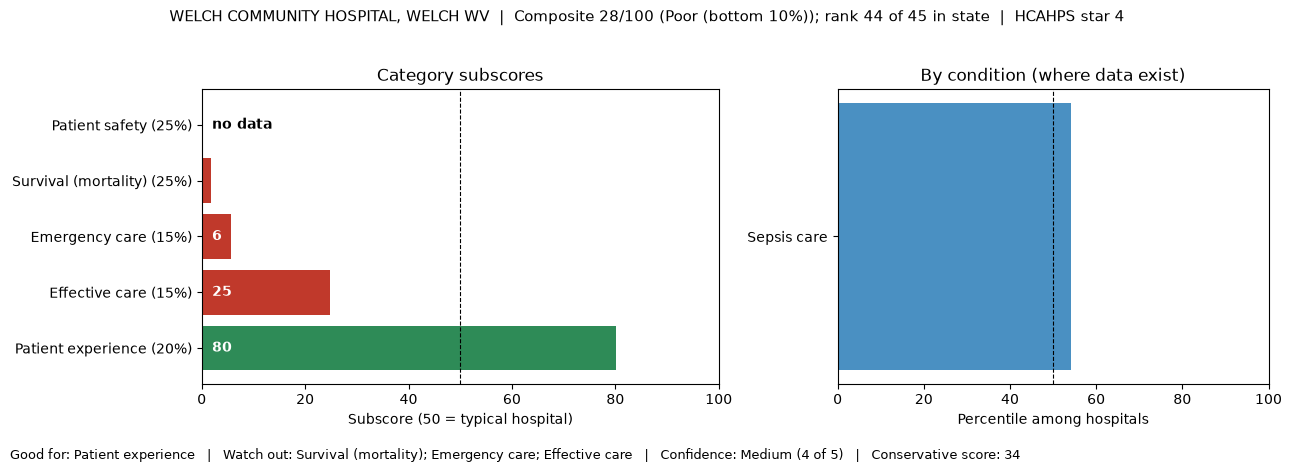


== low star, strong clinical


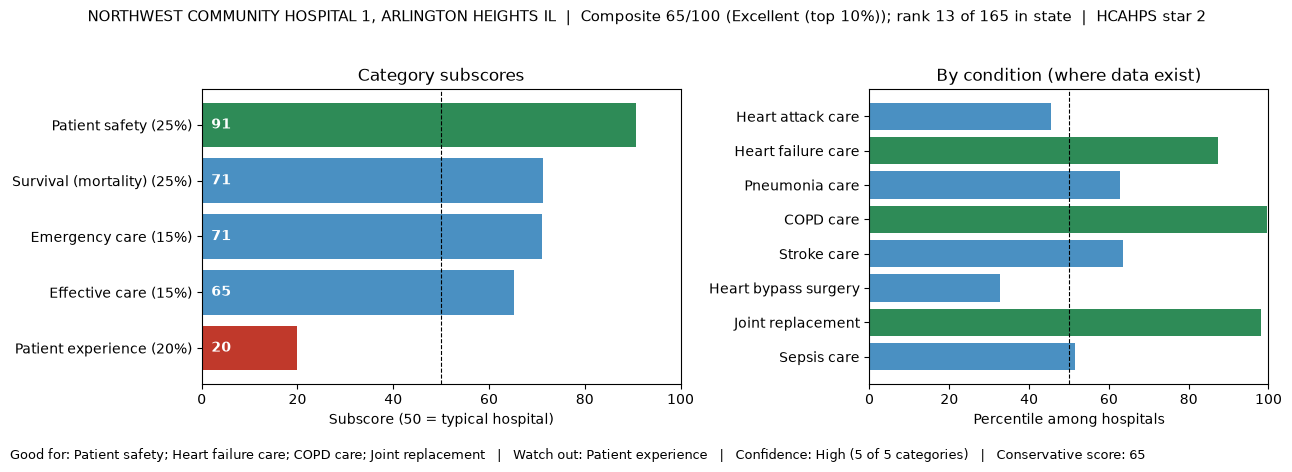

In [15]:
def scorecard(fid, save=True):
    r = T.set_index("facility_id").loc[fid]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
    vals = [r[c] for c in CATEGORY_WEIGHTS]; labs = [f"{CATEGORY_LABELS[c]} ({CATEGORY_WEIGHTS[c]:.0%})" for c in CATEGORY_WEIGHTS]
    cols = ["#bbbbbb" if pd.isna(v) else "#2e8b57" if v >= STRONG_CAT else "#c0392b" if v <= WEAK_CAT else "#4a90c2" for v in vals]
    ax[0].barh(labs[::-1], [0 if pd.isna(v) else v for v in vals][::-1], color=cols[::-1]); ax[0].axvline(50, color="k", ls="--", lw=.8); ax[0].set_xlim(0, 100)
    for i, v in enumerate(vals[::-1]): ax[0].text(2, i, "no data" if pd.isna(v) else f"{v:.0f}", va="center", color="white" if pd.notna(v) else "black", fontweight="bold")
    ax[0].set(xlabel="Subscore (50 = typical hospital)", title="Category subscores")
    sp = r[[c for c in r.index if c.startswith("spec_")]].astype(float).dropna(); sp.index = [i.replace("spec_", "") for i in sp.index]
    if len(sp):
        ax[1].barh(sp.index[::-1], sp.values[::-1], color=["#2e8b57" if v >= STRONG_SPEC else "#c0392b" if v <= 100 - STRONG_SPEC else "#4a90c2" for v in sp.values[::-1]]); ax[1].axvline(50, color="k", ls="--", lw=.8); ax[1].set_xlim(0, 100)
    ax[1].set(xlabel="Percentile among hospitals", title="By condition (where data exist)")
    stars = "no HCAHPS star" if pd.isna(r.hcahps_star) else f"HCAHPS star {int(r.hcahps_star)}"
    fig.suptitle(f"{r.facility_name}, {r.city} {r.state}  |  Composite {r.composite:.0f}/100 ({r.tier}); rank {int(r.rank_in_state)} of {int(r.n_scored_in_state)} in state  |  {stars}", fontsize=11, y=1.03)
    fig.text(0.01, -0.04, f"Good for: {r.good_for or '(nothing stands out)'}   |   Watch out: {r.watch_out or '(none)'}   |   Confidence: {r.confidence}   |   Conservative score: {r.composite_conservative:.0f}", fontsize=9)
    plt.tight_layout()
    if save: plt.savefig(OUT_DIR / "figures" / f"scorecard_{fid}.png", dpi=150, bbox_inches="tight")
    plt.show()

ex = T[T.composite.notna() & T.hcahps_star.notna()].copy()
picks = {"highest composite": ex.sort_values("composite").facility_id.iloc[-1],
         "high star, weak clinical": ex[(ex.hcahps_star >= 4)].sort_values("clinical_composite").facility_id.iloc[0],
         "low star, strong clinical": ex[(ex.hcahps_star <= 2)].sort_values("clinical_composite").facility_id.iloc[-1]}
for label, fid in picks.items():
    print("\n==", label); scorecard(fid)

## 12. ZIP-code visualizations
Map uses the optional `zipcodes` package for ZIP coordinates (`pip install zipcodes`); without it only the ranking charts are drawn.

zipcodes package not available; skipping the map: No module named 'zipcodes'


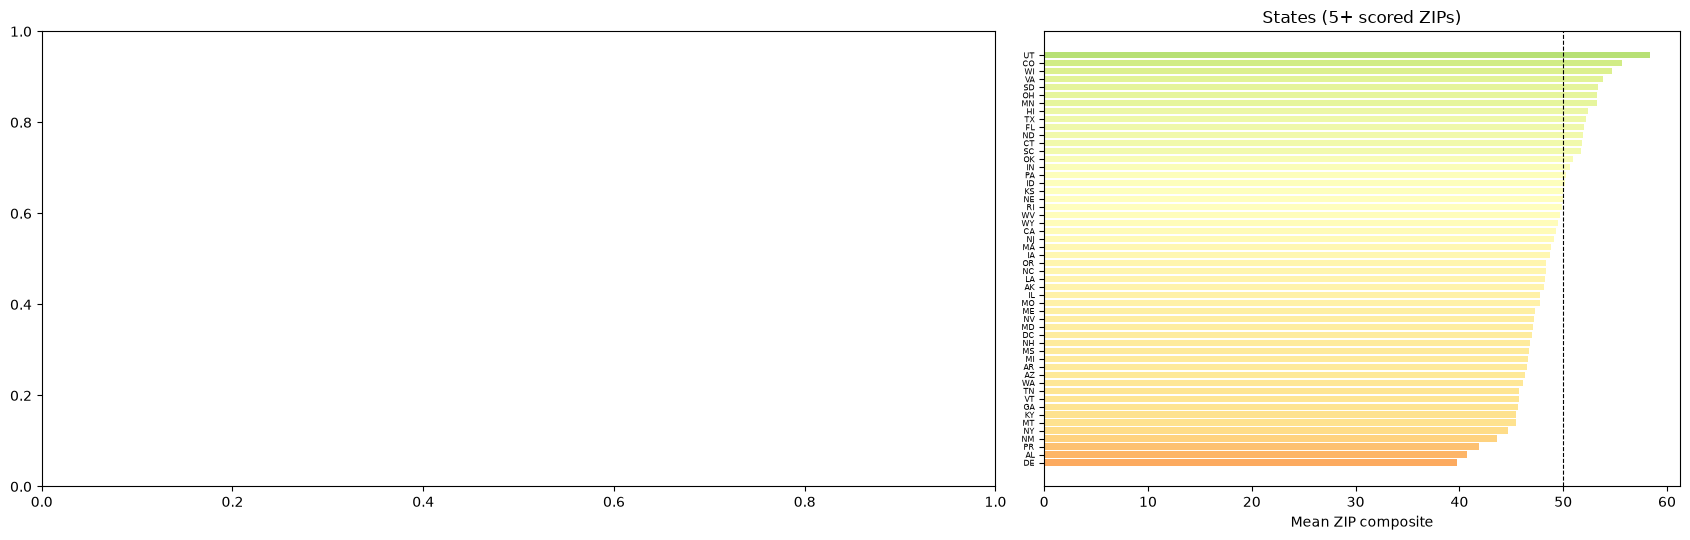

ZIP 77030 (HOUSTON, TX): score 59/100 (Good) from 6 hospital(s); best: TEXAS ORTHOPEDIC HOSPITAL
  Good for: Survival (mortality) | Watch out: -
                          facility_name  composite                tier  hcahps_star                                                                               good_for
              TEXAS ORTHOPEDIC HOSPITAL  72.479219 Excellent (top 10%)          4.0                                  Patient safety; Patient experience; Joint replacement
             HOUSTON METHODIST HOSPITAL  71.978838 Excellent (top 10%)          4.0 Survival (mortality); Heart attack care; Heart failure care; Pneumonia care; COPD care
              HOUSTON VA MEDICAL CENTER  63.837119                Good          4.0 Survival (mortality); Heart attack care; Heart failure care; Pneumonia care; COPD care
         Baylor St Lukes Medical Center  55.523058             Average          2.0            Survival (mortality); Heart attack care; Heart failure care; Pneumonia care


In [16]:
try:
    import zipcodes
    ll = {z["zip_code"]: (float(z["long"]), float(z["lat"])) for z in zipcodes.list_all() if z.get("lat") and z.get("long")}
except Exception as e:
    ll = {}; print("zipcodes package not available; skipping the map:", e)
Zp = Z.copy(); Zp[["lon", "lat"]] = pd.DataFrame([ll.get(z, (np.nan, np.nan)) for z in Zp.zip], index=Zp.index)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
m = Zp.dropna(subset=["lon"]); m = m[(m.lon > -128) & (m.lon < -65) & (m.lat > 24) & (m.lat < 50)]
if len(m):
    s = ax[0].scatter(m.lon, m.lat, c=m.zip_score, cmap="RdYlGn", s=10 + 6 * m.n_hospitals_scored, alpha=.8, vmin=25, vmax=75, edgecolors="none")
    plt.colorbar(s, ax=ax[0], label="ZIP composite score"); ax[0].set(title="ZIP-level composite score (contiguous US; dot size = hospitals in ZIP)", xticks=[], yticks=[]); ax[0].set_aspect(1.25)
st_tbl = Z.groupby("state").agg(zip_score=("zip_score", "mean"), n=("zip", "size")).query("n >= 5").sort_values("zip_score")
ax[1].barh(st_tbl.index, st_tbl.zip_score, color=plt.cm.RdYlGn((st_tbl.zip_score - 25) / 50)); ax[1].axvline(50, color="k", ls="--", lw=.8)
ax[1].set(xlabel="Mean ZIP composite", title="States (5+ scored ZIPs)"); ax[1].tick_params(axis="y", labelsize=6)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures" / "zip_map_and_states.png", dpi=150); plt.show()

def zip_scorecard(z):
    r = Z[Z.zip == z]
    if r.empty: print(f"No scored hospital in ZIP {z}"); return
    r = r.iloc[0]; print(f"ZIP {z} ({r.city}, {r.state}): score {r.zip_score:.0f}/100 ({r.zip_tier}) from {int(r.n_hospitals_scored)} hospital(s); best: {r.best_hospital}")
    print("  Good for:", r.good_for or "-", "| Watch out:", r.watch_out or "-")
    print(sc[sc.zip == z][["facility_name", "composite", "tier", "hcahps_star", "good_for"]].sort_values("composite", ascending=False).to_string(index=False))
zip_scorecard(Z.sort_values("n_hospitals_scored").zip.iloc[-1])

## 13. Outputs written to `Scoring_system/outputs/`
`hospital_scores.csv` (composite, subscores, points per category, tier, good_for / watch_out, ranks, HCAHPS star), `zip_scores.csv`, `validation_results.csv`, `scoring_config.csv`, and `figures/`.

In [17]:
CFG.assign(category_weight=CFG.category.map(CATEGORY_WEIGHTS)).to_csv(OUT_DIR / "scoring_config.csv", index=False)
sens.describe().round(4).to_csv(OUT_DIR / "weight_sensitivity_summary.csv")
print(sorted(p.name for p in OUT_DIR.glob("*.csv")), "|", len(list((OUT_DIR / "figures").glob("*.png"))), "figures")

['hospital_scores.csv', 'scoring_config.csv', 'validation_results.csv', 'weight_sensitivity_summary.csv', 'zip_scores.csv'] | 6 figures
